# House Prices - Modelling

Several regression models are trained and compared on the processed features from
[`01-Feature-Engineering.ipynb`](01-Feature-Engineering.ipynb) and the best one is selected
by cross-validated RMSE (on the log price).

**Models compared**
- Linear Regression (baseline)
- Ridge / Lasso (regularised linear)
- Random Forest
- Gradient Boosting

## 1. Imports & load processed data

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)

PROC = Path("../data/processed")
train = pd.read_csv(PROC / "train_processed.csv")
X = train.drop(columns=["SalePrice_Log1p"])
y = train["SalePrice_Log1p"]
print("X:", X.shape, "| y:", y.shape)

X: (1460, 236) | y: (1460,)


## 2. Cross-validation helper

The competition is scored on RMSE of `log(SalePrice)`, which is exactly the target built
here. 5-fold CV is used to estimate generalisation error.

In [2]:
def rmse_cv(model, X, y, k=5):
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    neg = cross_val_score(model, X, y, scoring="neg_root_mean_squared_error", cv=kf)
    return -neg

## 3. Compare models

In [3]:
models = {
    "LinearRegression": LinearRegression(),
    "Ridge":  make_pipeline(RobustScaler(), Ridge(alpha=10.0)),
    "Lasso":  make_pipeline(RobustScaler(), Lasso(alpha=0.001, max_iter=10000)),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42
    ),
}

scores = {}
for name, model in models.items():
    s = rmse_cv(model, X, y)
    scores[name] = s
    print(f"{name:18s}  RMSE = {s.mean():.4f}  +/- {s.std():.4f}")

LinearRegression    RMSE = 46232999.2272  +/- 77811803.8457


Ridge               RMSE = 0.1310  +/- 0.0198


Lasso               RMSE = 0.1302  +/- 0.0201


RandomForest        RMSE = 0.1423  +/- 0.0186


GradientBoosting    RMSE = 0.1308  +/- 0.0171


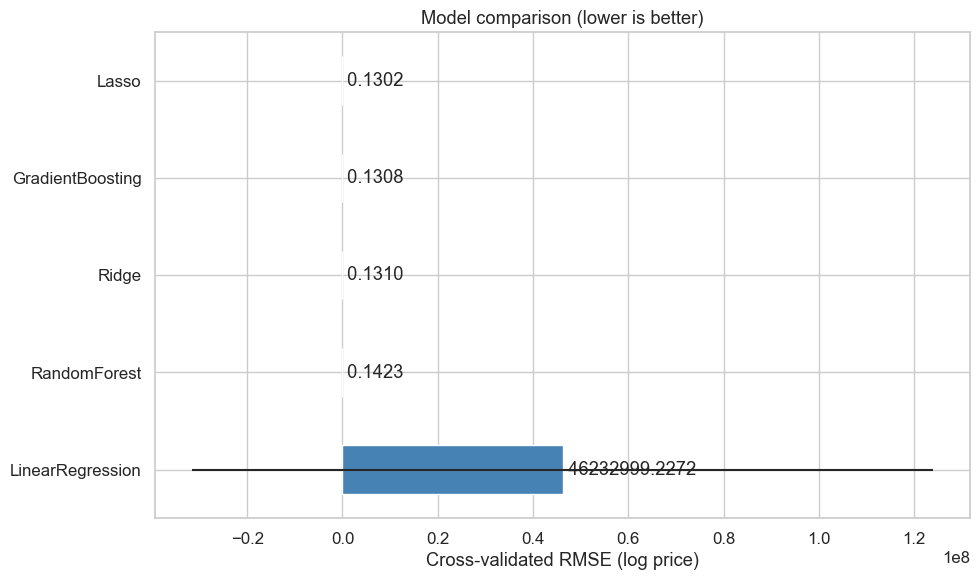

,mean,std
Lasso,1.302335e-01,2.007012e-02
GradientBoosting,1.308399e-01,1.708520e-02
Ridge,1.309887e-01,1.975342e-02
RandomForest,1.422656e-01,1.857268e-02
LinearRegression,4.623300e+07,7.781180e+07


In [4]:
summary = (
    pd.DataFrame({k: [v.mean(), v.std()] for k, v in scores.items()}, index=["mean", "std"])
    .T.sort_values("mean")
)

ax = summary["mean"].plot(kind="barh", xerr=summary["std"], color="steelblue")
ax.invert_yaxis()
ax.set_xlabel("Cross-validated RMSE (log price)")
ax.set_title("Model comparison (lower is better)")
for i, v in enumerate(summary["mean"]):
    ax.text(v, i, f" {v:.4f}", va="center")
plt.tight_layout()
plt.show()
summary

## 4. Select & evaluate the best model

The model with the lowest mean CV RMSE is picked, checked on a held-out validation
split, then refit on **all** training data for the final submission.

In [5]:
best_name = summary.index[0]
best_model = models[best_name]
print("Best model:", best_name)

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
best_model.fit(X_tr, y_tr)
val_pred = best_model.predict(X_val)

val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
val_r2 = r2_score(y_val, val_pred)
print(f"Hold-out RMSE (log): {val_rmse:.4f}")
print(f"Hold-out R^2       : {val_r2:.4f}")

pd.DataFrame({"y_true": y_val.values, "y_pred": val_pred}).to_csv(
    PROC / "val_predictions.csv", index=False
)

Best model: Lasso
Hold-out RMSE (log): 0.1306
Hold-out R^2       : 0.9085


## 5. Feature importance

A Gradient Boosting model is also fit on the full data purely for interpretability, and
the top feature importances are saved for the evaluation notebook.

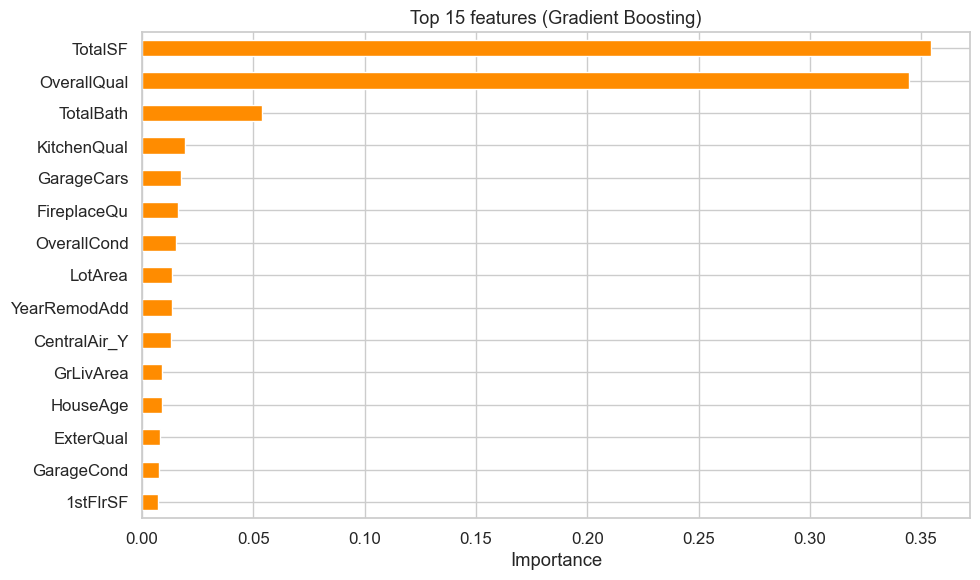

In [6]:
gbr = GradientBoostingRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42
).fit(X, y)

importance = (
    pd.Series(gbr.feature_importances_, index=X.columns)
    .sort_values(ascending=False)
)
importance.head(20).to_csv(PROC / "feature_importance.csv", header=["importance"])

importance.head(15).iloc[::-1].plot(kind="barh", color="darkorange")
plt.title("Top 15 features (Gradient Boosting)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 6. Refit on all data & persist the model

In [7]:
best_model.fit(X, y)
joblib.dump(best_model, PROC / "best_model.pkl")
print(f"Saved best model ({best_name}) -> data/processed/best_model.pkl")

Saved best model (Lasso) -> data/processed/best_model.pkl


### Output

The best model (and its validation predictions / feature importances) are saved to
`data/processed/`. Continue to [`03-Evaluation.ipynb`](03-Evaluation.ipynb) for
diagnostics and the submission file.